# Vision Transformer

在 Transformer 出现之前，以传统 CNN 为核心的架构一直是计算机视觉领域核心。随着 Transformer 在自然语言处理中取得了显著的突破，如何将其用于计算机视觉成为一个很有价值的研究方向。2021 年 [Vision Transformer](https://arxiv.org/abs/2010.11929) 发布，通过将图片切分并投影构造 Transformer Encoder 的输入，以及在 JFT-300M 大数据集上预训练，在当时接近甚至超越了在特定数据集上训练的 ResNet 的分类成绩。

ViT 总共提供了三个版本的模型，大小大致是参考当时的 BERT 和 GPT 设计的。想要用下面的比较大的模型复现出论文成果，需要再很大的数据集上进行预训练。所以本文将使用 tiny 化的模型在 CIFAR10 数据集上训练并预测，旨在理解 ViT 的架构和训练数据流，体会将图片转化为序列的思想。

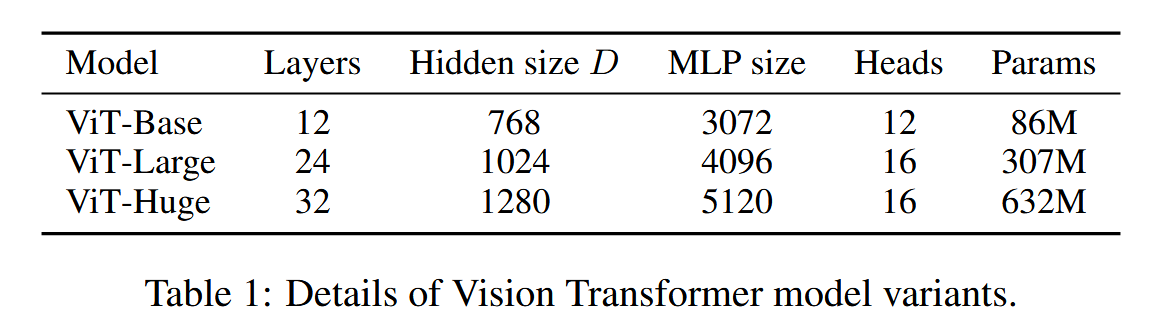

本文使用的模型参数如下：

| Models | Layers | Hidden size D | MLP size | Heads | Image size | Patch Size | Params |
|---|---|---|---|---|---|---|---|
| Tiny | 4 | 48 | 192 | 4 | 32 | 4 | 0.12M |
| ViT-Base | 12 | 768 | 3072 | 12 | 224 | 16 | 86M |



In [1]:
import torch
import torch.nn as nn

## 模型架构

ViT 使用了经典的 Transformer Encoder 架构，同时模仿 BERT 添加了 `<cls>` 特殊 token。在最后，通过对 `<cls>` 对应位置的模型输出向量，进行线性投影，构造分类头。

![ViT Architecture.png](<attachment:ViT Architecture.png>)
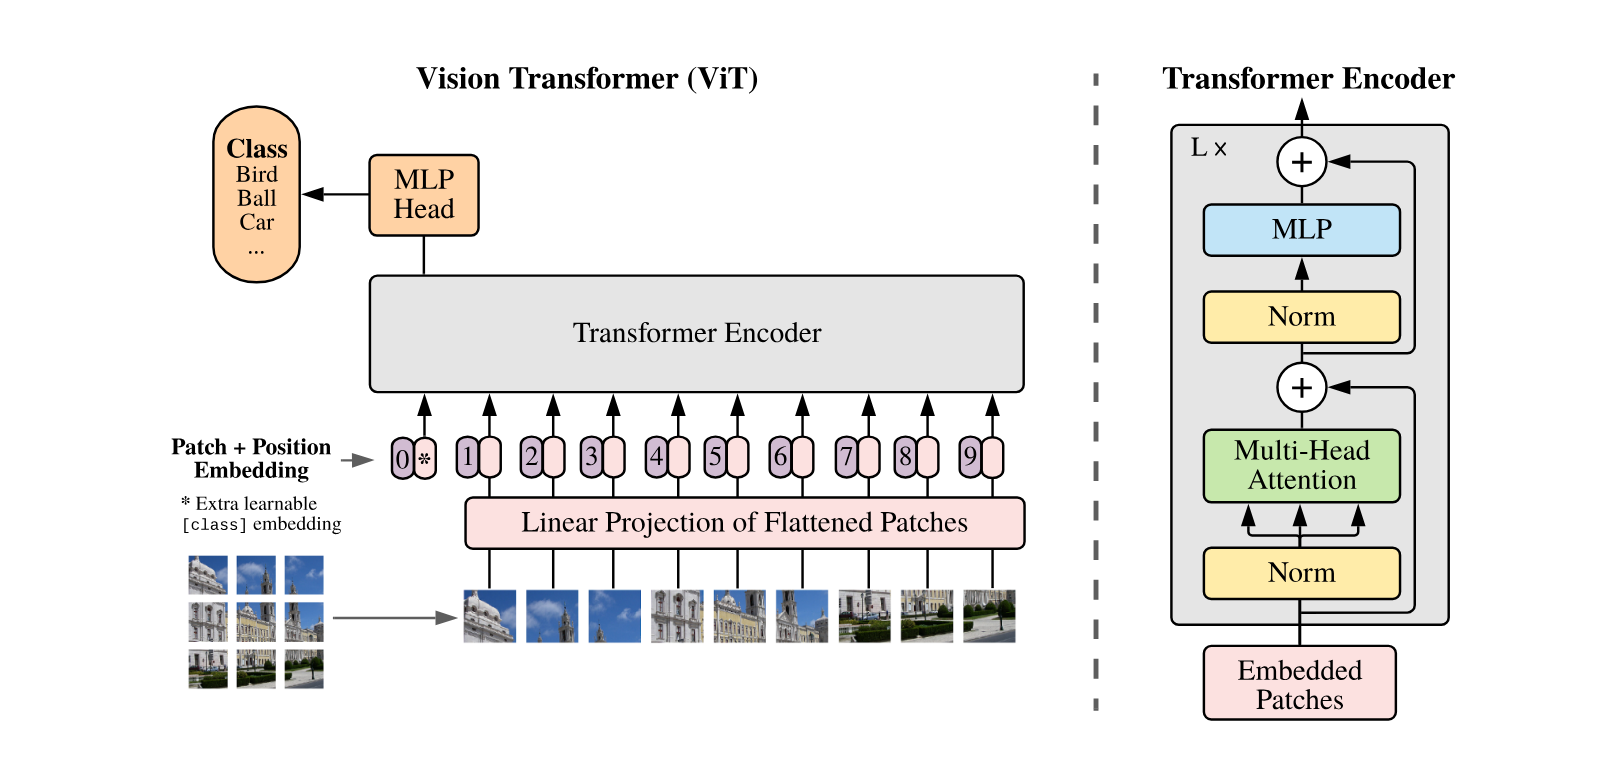

### Patch Embedding

Patch Embedding 是 ViT 的核心，负责处理怎么把图片变成一个 Transformer 能够处理的序列的问题。经过切 Patch 有可能会破坏图片原本的空间结构关系，但通过后续引入**可学习的位置编码**，模型能够自己学习出空间结构。对于 Patch 内的空间结构，由注意力层负责学习。


#### 数学定义

输入图像 $x \in \mathbb{R}^{H \times W \times C}$，patch 大小为 $P \times P$。我们需要把输入图像变为一个一维向量构成的序列，向量长度与模型 `hidden_size` 一致。

**1. 切成不重叠的 patch**

把图像切成 $N = \frac{H}{P} \times \frac{W}{P}$ 个 patch。  
每个 patch 大小是 $P \times P \times C$。

例如输入 $224\times224\times3$，patch 大小 $16\times16$，则：
$$
N = 14 \times 14 = 196
$$
也就是得到 196 个 patch。

**2. 每个 patch 展平成向量**

每个 patch 从 $P \times P \times C$ 展平成一个一维向量：
$$
x_p^i \in \mathbb{R}^{P^2 C}
$$
比如 $16\times16\times3 = 768$ 维。

所以图像变成：
$$
\{x_p^1, x_p^2, \dots, x_p^N\}
$$
每个 $x_p^i$ 是一个 768 维向量。

**3. 线性投影到 Transformer 的 embedding 维度**

用一个可学习的线性层把每个 patch 向量映射到维度 $D$：
$$
z_i = x_p^i E
$$
其中：
$$
E \in \mathbb{R}^{(P^2 C) \times D}
$$
这样每个 patch 变成一个 $D$ 维 token。

如果 $D=768$，那么每个 patch 从 768 维变成 768 维，但这只是巧合，实际由模型设定。

#### 代码实现

Patch Embedding 可以通过一个二维卷积进行等价的实现，参数这样设置：

- `kernel_size=P`：感受野正好一个 patch。
- `stride=P`：patch 之间不重叠。
- `out_channels=D`：投影到 Transformer 的 embedding 维度。
- `bias=True`：等价于线性层的 bias。
- 权重共享：所有 patch 共用同一个卷积核，等价于所有 patch 共用同一个线性投影矩阵。
- 二维卷积在这里不是用来提取局部特征的，而是作为“分块全连接”的高效实现。

```python
conv = nn.Conv2d(in_channels=C, out_channels=D, kernel_size=P, stride=P)
```

输入：

$$
X \in \mathbb{R}^{B \times C \times H \times W}
$$

输出：

$$
Y = \text{conv}(X) \in \mathbb{R}^{B \times D \times \frac{H}{P} \times \frac{W}{P}}
$$

此时每个空间位置 $(i,j)$ 对应原图中的一个 patch。

然后展平空间维度并转置：

```python
Y = Y.flatten(2)        # (B, D, N)
Y = Y.transpose(1, 2)   # (B, N, D)
```

得到：

$$
Z \in \mathbb{R}^{B \times N \times D}
$$

这正是 ViT 的 patch embedding 序列



In [2]:
class PatchEmbeddings(nn.Module):
    """
    将 image (num_channels * img_size * img_size) 转换成 seq (seq_len * hidden_siz)。
    其中 seq_len 就是 num_patches，数值上等于 (img_size // patch_size) ** 2
    """
    def __init__(self, config):
        super().__init__()
        self.image_size = config["image_size"]  # 图像边长
        self.patch_size = config["patch_size"]  # 每个切片的边长
        self.num_channels = config["num_channels"]  # 输入图像频道数
        self.hidden_size = config["hidden_size"]    # ViT 向量长度
        # 总共切多少块
        self.num_patches = (self.image_size // self.patch_size) ** 2
        # 用卷积层一次实现 切块、展平、投影
        self.projection = nn.Conv2d(self.num_channels, self.hidden_size, 
                                    kernel_size=self.patch_size, stride=self.patch_size)
    
    def forward(self, x):
        # x : (batch_size, num_channels, image_size, image_size)
        x = self.projection(x)  # (batch_size, hidden_size, img_size // patch_size, img_size // patch_size)
        x = x.flatten(2)        # flatten 按逻辑顺序展平。 (batch_size, hidden_size, num_patches)
        x = x.transpose(1, 2)   # (batch_size, num_patches, hidden_size)
        return x

### 用 patch embedding 组成整个嵌入层

ViT 还引入了特殊的可学习的 cls_token，以及使用可学习的位置编码。

**1. 加 class token**

在序列最前面拼接一个可学习的 class token：
$$
z_0 = [x_{\text{class}}; z_1; z_2; \dots; z_N]
$$
其中 $x_{\text{class}} \in \mathbb{R}^D$。

于是序列长度从 $N$ 变成 $N+1$。  
例如 196 个 patch token + 1 个 class token = 197 个 token。

**2. 加位置编码**
因为 Transformer 本身不知道 token 的顺序，而图像 patch 有空间位置关系，所以要加位置编码：
$$
z_0 = [x_{\text{class}}; z_1; \dots; z_N] + E_{\text{pos}}
$$
其中：
$$
E_{\text{pos}} \in \mathbb{R}^{(N+1) \times D}
$$
位置编码可以可学习，也可以用正弦编码。

最终得到：
$$
z_0 \in \mathbb{R}^{(N+1) \times D}
$$


In [3]:
class Embeddings(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.patch_embeddings = PatchEmbeddings(config)
        # 批量维度先保持为 1，forward 时再扩展
        self.cls_token = nn.Parameter(torch.randn(1, 1, config["hidden_size"]))
        self.position_embeddings = nn.Parameter(
            torch.randn(1, self.patch_embeddings.num_patches + 1, config["hidden_size"])
        )
        self.dropout = nn.Dropout(config["hidden_dropout_prob"])
    
    def forward(self, x):
        x = self.patch_embeddings(x)    # (batch_size, num_patches, hidden_size)
        batch_size, _, _ = x.size()
        # 扩展 cls token 并与 x concat
        cls_token = self.cls_token.expand(batch_size, -1, -1)
        x = torch.concat((cls_token, x), dim=1)
        # 广播机制，将位置编码加入序列
        x = x + self.position_embeddings
        x = self.dropout(x)
        return x

### 多头注意力

MHA 的实现和 Transformer 一致。这里直接按照 nanoGPT 中的方式实现，区别是**不再需要使用因果掩码**，图像序列并没有严格的时间顺序信息。

In [4]:
import math
from torch.nn import functional as F

class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.hidden_size = config["hidden_size"]
        self.num_heads = config["num_attention_heads"]
        self.qkv_bias = config["qkv_bias"]
        # 每个头处理的向量的长度
        assert self.hidden_size % self.num_heads == 0, "hid_size must be divisible by n_heads"
        self.head_dims = self.hidden_size // self.num_heads
        # QKV 权重
        self.W_attn = nn.Linear(self.hidden_size, 3 * self.hidden_size)
        self.attn_droupout = nn.Dropout(config["attention_probs_dropout_prob"])
        # 输出投影
        self.out_proj = nn.Linear(self.hidden_size, self.hidden_size)
        self.out_dropout = nn.Dropout(config["hidden_dropout_prob"])
        
    # 留一个获取注意力权重的接口，便于可视化
    def forward(self, x, output_attentions=False):
        batch_size, seq_len, _ = x.size()
        qkv = self.W_attn(x)    # (batch_size, seq_len, 3 * hidden_size)
        # 分割
        q, k, v = qkv.split(self.hidden_size, dim=2)
        k = k.reshape(batch_size, seq_len, self.num_heads, self.head_dims).transpose(1, 2)
        q = q.reshape(batch_size, seq_len, self.num_heads, self.head_dims).transpose(1, 2)
        v = v.reshape(batch_size, seq_len, self.num_heads, self.head_dims).transpose(1, 2)
        # 缩放点积注意力
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = F.softmax(att, dim=-1)
        att = self.attn_droupout(att)
        y = att @ v
        # 恢复形状，线性投影，输出
        y = y.transpose(1, 2).reshape(batch_size, seq_len, self.hidden_size)
        y = self.out_dropout(self.out_proj(y))
        if not output_attentions:
            return (y, None)
        else:
            return (y, att)

### 使用近似 GELU 激活函数的 FFN

In [5]:
class NewGELUActivation(nn.Module):
    """tanh 近似的 GELU 激活函数"""
    def forward(self, input):
        return 0.5 * input * (1.0 + torch.tanh(math.sqrt(2.0 / math.pi) * (input + 0.044715 * torch.pow(input, 3.0))))

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.dense_1 = nn.Linear(config["hidden_size"], config["intermediate_size"])
        self.activation = NewGELUActivation()
        self.dense_2 = nn.Linear(config["intermediate_size"], config["hidden_size"])
        self.dropout = nn.Dropout(config["hidden_dropout_prob"])
    
    def forward(self, x):
        x = self.dense_1(x)
        x = self.activation(x)
        x = self.dense_2(x)
        x = self.dropout(x)
        return x

### 构造 Transformer 块和 Encoder

In [6]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.att = MultiHeadAttention(config)
        self.mlp = MLP(config)
        self.norm1 = nn.LayerNorm(config["hidden_size"])
        self.norm2 = nn.LayerNorm(config["hidden_size"])
    
    def forward(self, x, output_attentions=False):
        att_out, att_probs = self.att(self.norm1(x), output_attentions=output_attentions)
        x = x + att_out
        mlp_out = self.mlp(self.norm2(x))
        x = x + mlp_out
        if not output_attentions:
            return (x, None)
        else:
            return (x, att_probs)

In [7]:
class Encoder(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.blocks = nn.ModuleList(
            [Block(config) for _ in range(config["num_hidden_layers"])]
        )
    
    def forward(self, x, output_attentions=False):
        all_attentions = []
        for blk in self.blocks:
            x, att_probs = blk(x, output_attentions=output_attentions)
            if output_attentions:
                all_attentions.append(att_probs)
        if not output_attentions:
            return (x, None)
        else:
            return (x, all_attentions)

### 接分类头的 ViT 架构

可以通过改变输出层的架构，实现不同的 ViT 模型。这里直接使用分类头。

需要留意**权重初始化**：原始 ViT 通常对所有 Linear/Conv 权重都用 truncated normal；而 HuggingFace 和本文对 Linear/Conv2d 用的是普通 normal_，只对 position_embeddings 和 cls_token 用 trunc_normal_。

trunc_normal 是**截断正态初始化**：从正态分布中采样，但把值限制在 [a, b] 内，去掉极端值。它的作用是让初始化更稳定、更安全，支持更深层的模型。

In [8]:
class ViTForClassification(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.image_size = config["image_size"]
        self.hidden_size = config["hidden_size"]
        self.num_classes = config["num_classes"]    # 数据集需要分类的种类数量
        # 创建模块
        self.embedding = Embeddings(config)
        self.encoder = Encoder(config)
        # 分类头
        self.classifier = nn.Linear(self.hidden_size, self.num_classes)

        # 权重初始化
        self.apply(self._init_weights)

    def forward(self, x, output_attentions=False):
        """ViT 推理，返回 (logits, att_probs)"""
        embedded = self.embedding(x)    # (batch_size, seq_len, hidden_size)
        encoder_output, all_attentions = self.encoder(
            embedded, output_attentions=output_attentions
        )
        # 对 cls 特殊词元进行分类
        logits = self.classifier(encoder_output[:, 0, :])
        if not output_attentions:
            return (logits, None)
        else:
            return (logits, all_attentions)

    # 权重初始化
    def _init_weights(self, module):
        # 对线性层用正态初始化，偏置用 0 初始化
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            torch.nn.init.normal_(module.weight, mean=0.0, std=self.config["initializer_range"])
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        # 对于 LayerNorm 的参数，权重（缩放）用 1，偏置（偏移）用 0
        # 这样 LayerNorm 初始时仿射变换相当于恒等变换，只做归一化，不会额外缩放或偏移
        elif isinstance(module, nn.LayerNorm):
            module.bias.data.zero_()
            module.weight.data.fill_(1.0)
        # 对于嵌入层，有两个权重需要初始化，分别都用截断正态初始化
        elif isinstance(module, Embeddings):
            module.position_embeddings.data = nn.init.trunc_normal_(
                module.position_embeddings.data.to(torch.float32),
                mean=0.0,
                std=self.config["initializer_range"],
            ).to(module.position_embeddings.dtype)

            module.cls_token.data = nn.init.trunc_normal_(
                module.cls_token.data.to(torch.float32),
                mean=0.0,
                std=self.config["initializer_range"],
            ).to(module.cls_token.dtype)

## 模型参数和数据准备

### 模型参数设定

按照下方设定，初始化我们的 ViT 模型。

In [9]:
config = {
    "patch_size": 4,                # patch 块边长
    "hidden_size": 48,              # Transformer 向量长度
    "num_hidden_layers": 4,         # 模型 Block 层数
    "num_attention_heads": 4,       # 注意力头数
    "intermediate_size": 4 * 48,    # FFN 隐藏层长度 4 * hidden_size
    "hidden_dropout_prob": 0.0,     # MLP Dropout
    "attention_probs_dropout_prob": 0.0,    # attention_probs Dropout
    "initializer_range": 0.02,      # 初始化正态函数的标准差
    "image_size": 32,               # 输入图片边长
    "num_classes": 10,              # 模型需要分类的种类数，CIFAR10 是 10 类
    "num_channels": 3,              # 输入图片频道数，这里是 RGB
    "qkv_bias": True,               # QKV 投影是否使用 bias
}

model = ViTForClassification(config)

到这里我们已经完成了 tiny ViT 模型架构，可以测试一下输入输出。

In [10]:
batch_size = 4
image_size = 32
num_channels = 3
test_x = torch.randn(batch_size, num_channels, image_size, image_size)
print(test_x.shape)

# 因为预留返回 att_probs 的空间，所以 y 是一个 tuple，第 0 维是 logits 输出
y = model(test_x)
print(y[0].shape)

torch.Size([4, 3, 32, 32])
torch.Size([4, 10])


### 图像预处理

对于下载的 CIFAR10 原始数据集，就像 ResNet 一样，我们不会直接把图片输入模型。CIFAR10 的数据是 50,000 张 32*32 的 RGB 通道的图像，颜色使用 uint8 存储，存储顺序为 HWC（高宽色）。

1. ToTensor: 维度从 HWC 变成 CHW；
数值从 0~255 除以 255，变成 float32, 0~1。

In [11]:
import torchvision.transforms as transforms
transforms.ToTensor()

ToTensor()

2. Resize: 把图像缩放到 32×32。用于统一接口，对 CIFAR10 实际上没有变化。

In [12]:
transforms.Resize((32, 32))

Resize(size=(32, 32), interpolation=bilinear, max_size=None, antialias=True)

3. RandomHorizontalFlip: 以一定概率水平翻转图像。数据增强常用手段，减轻模型过拟合。

In [13]:
transforms.RandomHorizontalFlip(p=0.5)

RandomHorizontalFlip(p=0.5)

4. 随机裁剪一块区域，并使用插值法 resize 回指定的大小。目的是让 ViT 在训练时看到同一张图的不同局部和尺度版本，提高泛化能力。
   
   这里的设置为：裁剪面积占原图面积的 80% ~ 100%；裁剪框宽高比在 0.75 ~ 1.3333，也就是 3/4 ~ 4/3；裁剪区域 resize 回 32×32；interpolation=2 通常对应双线性插值。

In [14]:
transforms.RandomResizedCrop(size=(32, 32),
                             scale=(0.8, 1.0),
                             ratio=(0.75, 1.3333333333333333),
                             interpolation=2)

RandomResizedCrop(size=(32, 32), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)

5. 对每个通道做归一化，统一均值和标准差。
   
   这里相当于对每个通道做 `x_norm = (x - 0.5) / 0.5 = 2 * x - 1`。因为前面 ToTensor() 后数值是 [0, 1]，所以 Normalize 后变成 [-1, 1]，近似零均值。这对 ViT 训练比较友好，因为 Transformer 里的 LayerNorm、线性层通常希望输入分布稳定。

In [15]:
transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))

对于测试集，不做随机增强：
- 不做 RandomHorizontalFlip；
- 不做 RandomResizedCrop；
- 只做 ToTensor、Resize、Normalize。

### 训练数据

下载 CIFAR10 数据集并加载进 dataloader。这里直接使用 torch 封装好的 datasets，我们只需要调用接口，划分好训练数据和测试数据即可。

In [16]:
import torch
import torchvision
import torchvision.transforms as transforms

def prepare_data(batch_size=4, num_workers=2,
                 train_sample_size=None, test_sample_size=None):
    # 定义对下载的 PIL Image 进行的数据操作
    train_transform = transforms.Compose(
        [transforms.ToTensor(),
        transforms.Resize((32, 32)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomResizedCrop((32, 32), scale=(0.8, 1.0), ratio=(0.75, 1.3333333333333333), interpolation=2),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
    # 下载数据集，并将变换作用于数据集上
    trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                            download=True, transform=train_transform)
    # train_sample_size 取原数据集的子集的大小，随机取样
    if train_sample_size is not None:
        indices = torch.randperm(len(trainset))[:train_sample_size]
        trainset = torch.utils.data.Subset(trainset, indices)

    # 对于测试数据，不做随机水平翻转和随机切片
    test_transform = transforms.Compose(
        [transforms.ToTensor(),
        transforms.Resize((32, 32)),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
    testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=test_transform)
    if test_sample_size is not None:
        indices = torch.randperm(len(testset))[:test_sample_size]
        testset = torch.utils.data.Subset(testset, indices)

    # 把训练数据和测试数据加载进 DataLoader 中
    # DataLoader 的功能类似于迭代器，返回 batch 化的数据
    trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                              shuffle=True, num_workers=num_workers)
    testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                             shuffle=False, num_workers=num_workers)

    # Data 中的类别用数字索引表示，这里给出映射表
    classes = ('plane', 'car', 'bird', 'cat', 'deer', 
               'dog', 'frog', 'horse', 'ship', 'truck')
    return trainloader, testloader, classes

## 训练和评估模型

### 保存训练记录和模型

定义辅助函数，把模型的配置文件、训练的阶段性 loss acc、最终模型存入磁盘。

In [17]:
import json, os, math
import matplotlib.pyplot as plt
import numpy as np

def save_experiment(experiment_name, config, model, train_losses, test_losses,
                    accuracies, base_dir="experiments"):
    """
    将训练的信息存入磁盘，在当前路径的 experiments/experiment_name 文件夹下保存。
    
    experiment_name：自定义实验名称
    config：模型设置字典
    model：训练完成的 ViT 模型
    train_losses：训练过程中每个 epoch 模型在训练集上的 loss
    test_losses：训练过程中每个 epoch 模型在测试集上的 loss
    accuracies：训练过程中每个 epoch 模型在测试集上的分类 acc
    """
    # 创建路径
    outdir = os.path.join(base_dir, experiment_name)
    os.makedirs(outdir, exist_ok=True)

    # 保存模型的超参数设置
    configfile = os.path.join(outdir, 'config.json')
    with open(configfile, 'w') as f:
        json.dump(config, f, sort_keys=True, indent=4)

    # 保存训练日志
    jsonfile = os.path.join(outdir, 'metrics.json')
    with open(jsonfile, 'w') as f:
        data = {
            'train_losses': train_losses,
            'test_losses': test_losses,
            'accuracies': accuracies,
        }
        json.dump(data, f, sort_keys=True, indent=4)

    # 保存 pytorch 模型
    save_checkpoint(experiment_name, model, "final", base_dir=base_dir)

def save_checkpoint(experiment_name, model, epoch, base_dir="experiments"):
    # 创建路径
    outdir = os.path.join(base_dir, experiment_name)
    os.makedirs(outdir, exist_ok=True)
    # 创建文件并保存
    cpfile = os.path.join(outdir, f'model_{epoch}.pt')
    torch.save(model.state_dict(), cpfile)

同时给出读取这些文件的函数，用于后续可视化。

In [18]:
def load_experiment(experiment_name, checkpoint_name="model_final.pt", base_dir="experiments"):
    outdir = os.path.join(base_dir, experiment_name)
    # 读取配置文件
    configfile = os.path.join(outdir, 'config.json')
    with open(configfile, 'r') as f:
        config = json.load(f)
    # 读取该模型的训练日志
    jsonfile = os.path.join(outdir, 'metrics.json')
    with open(jsonfile, 'r') as f:
        data = json.load(f)
    train_losses = data['train_losses']
    test_losses = data['test_losses']
    accuracies = data['accuracies']
    # 加载模型权重
    model = ViTForClassification(config)
    cpfile = os.path.join(outdir, checkpoint_name)
    model.load_state_dict(torch.load(cpfile))
    return config, model, train_losses, test_losses, accuracies

### 训练和评估流程

与 Transformer 基本一致。这里使用类来实现。

In [19]:
class Trainer:
    def __init__(self, model, optimizer, loss_fn, exp_name, device):
        self.model = model.to(device)
        self.optimizer = optimizer
        self.loss_fn = loss_fn
        self.exp_name = exp_name
        self.device = device

    def train_epoch(self, trainloader):
        """训练一个 epoch，即过一遍完整训练集，返回平均损失"""
        self.model.train()  # 设置为训练模式
        total_loss = 0      # 记录这个 epoch 总的 loss
        for batch in trainloader:
            x, y = batch
            x, y = x.to(self.device), y.to(self.device)
            
            self.optimizer.zero_grad()
            loss = self.loss_fn(self.model(x)[0], y)
            loss.backward()
            self.optimizer.step()
            
            total_loss += loss.item() * len(x)
        return total_loss / len(trainloader.dataset)
    
    @torch.no_grad()
    def evaluate(self, testloader):
        """评估模型在测试集上的表现，返回 acc 和 平均损失"""
        self.model.eval()   # 设置为评估模式
        total_loss = 0      # 记录这个在测试集上的 loss
        correct = 0         # 记录分类正确的个数
        with torch.no_grad():
            for batch in testloader:
                x, y = batch
                x, y = x.to(self.device), y.to(self.device)
                
                logits, _ = self.model(x)
                loss = self.loss_fn(logits, y)
                total_loss += loss.item() * len(x)
                
                predictions = torch.argmax(logits, dim=1)
                correct += torch.sum(predictions == y).item()
        accuracy = correct / len(testloader.dataset)
        avg_loss = total_loss / len(testloader.dataset)
        return accuracy, avg_loss
    
    def train(self, trainloader, testloader, epochs, save_model_every_n_epochs=0):
        # 记录每个 epoch 的 loss 和 acc
        train_losses, test_losses, accuracies = [], [], []
        # 按 epoch 训练模型
        for i in range(epochs):
            train_loss = self.train_epoch(trainloader)
            accuracy, test_loss = self.evaluate(testloader)
            train_losses.append(train_loss)
            test_losses.append(test_loss)
            accuracies.append(accuracy)
            print(f"Epoch: {i+1}, Train loss: {train_loss:.4f}, Test loss: {test_loss:.4f}, Accuracy: {accuracy:.4f}")
            # 设置了每多少个 epoch 保存一次模型
            if save_model_every_n_epochs > 0 and (i+1) % save_model_every_n_epochs == 0 and i+1 != epochs:
                print('\tSave checkpoint at epoch', i+1)
                save_checkpoint(self.exp_name, self.model, i+1)
        # 保存模型
        save_experiment(self.exp_name, config, self.model, train_losses, test_losses, accuracies)

### 运行训练

设置超参数。

In [20]:
exp_name = 'vit-with-50-epochs' #@param {type: "string"}
batch_size = 512                 #@param {type: "integer"}
epochs = 50                     #@param {type: "integer"}
lr = 1e-2                       #@param {type: "number"}
save_model_every = 0            #@param {type: "integer"}

device = "cuda" if torch.cuda.is_available() else "cpu"

训练主程序。ViT 使用 AdamW 优化器和交叉熵损失函数。

In [21]:
def main():
    save_model_every_n_epochs = save_model_every
    # 加载 CIFAR10 数据集
    trainloader, testloader, _ = prepare_data(batch_size=batch_size)
    # 创建模型，优化器，损失函数并训练
    model = ViTForClassification(config)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    loss_fn = nn.CrossEntropyLoss()
    trainer = Trainer(model, optimizer, loss_fn, exp_name, device=device)
    trainer.train(trainloader, testloader, epochs, save_model_every_n_epochs=save_model_every_n_epochs)

运行训练。

In [ ]:
if __name__ == '__main__':
    main()

Epoch: 1, Train loss: 1.9511, Test loss: 1.8844, Accuracy: 0.3311
Epoch: 2, Train loss: 1.6484, Test loss: 1.4989, Accuracy: 0.4500
Epoch: 3, Train loss: 1.4887, Test loss: 1.4105, Accuracy: 0.4900
Epoch: 4, Train loss: 1.4137, Test loss: 1.3599, Accuracy: 0.5085
Epoch: 5, Train loss: 1.3630, Test loss: 1.3492, Accuracy: 0.5065
Epoch: 6, Train loss: 1.3027, Test loss: 1.2639, Accuracy: 0.5372
Epoch: 7, Train loss: 1.2607, Test loss: 1.2143, Accuracy: 0.5603
Epoch: 8, Train loss: 1.2230, Test loss: 1.2049, Accuracy: 0.5624
Epoch: 9, Train loss: 1.1901, Test loss: 1.1850, Accuracy: 0.5707
Epoch: 10, Train loss: 1.1667, Test loss: 1.2190, Accuracy: 0.5672
Epoch: 11, Train loss: 1.1325, Test loss: 1.1705, Accuracy: 0.5770
Epoch: 12, Train loss: 1.1110, Test loss: 1.1594, Accuracy: 0.5857
Epoch: 13, Train loss: 1.0897, Test loss: 1.1206, Accuracy: 0.5945
Epoch: 14, Train loss: 1.0726, Test loss: 1.1062, Accuracy: 0.5893
Epoch: 15, Train loss: 1.0349, Test loss: 1.0611, Accuracy: 0.6235
Epoc

## 可视化

### 展示 CIFAR10 中的部分数据

随机选择 30 张图片打印出来，同时附上标签。

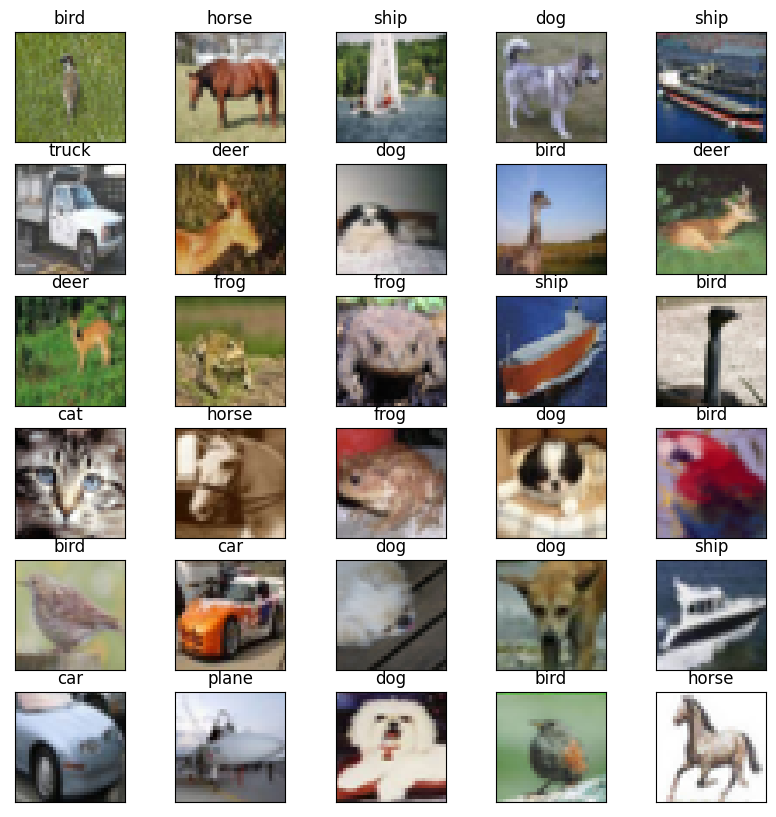

In [23]:
def visualize_images():
    trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                            download=True)
    classes = ('plane', 'car', 'bird', 'cat',
            'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    # 随机选择 30 张样本，取出 Image 和 Label
    indices = torch.randperm(len(trainset))[:30]
    images = [np.asarray(trainset[i][0]) for i in indices]
    labels = [trainset[i][1] for i in indices]
    # 使用 plot 打印
    fig = plt.figure(figsize=(10, 10))
    for i in range(30):
        ax = fig.add_subplot(6, 5, i+1, xticks=[], yticks=[])
        ax.imshow(images[i])
        ax.set_title(classes[labels[i]])

visualize_images()

### 可视化训练日志

通过加载上一节中保存的训练日志，绘制 loss-epoch 以及 acc-epoch 曲线观察模型的学习过程。同时可以通过 loss-epoch 曲线观察是否出现过拟合。

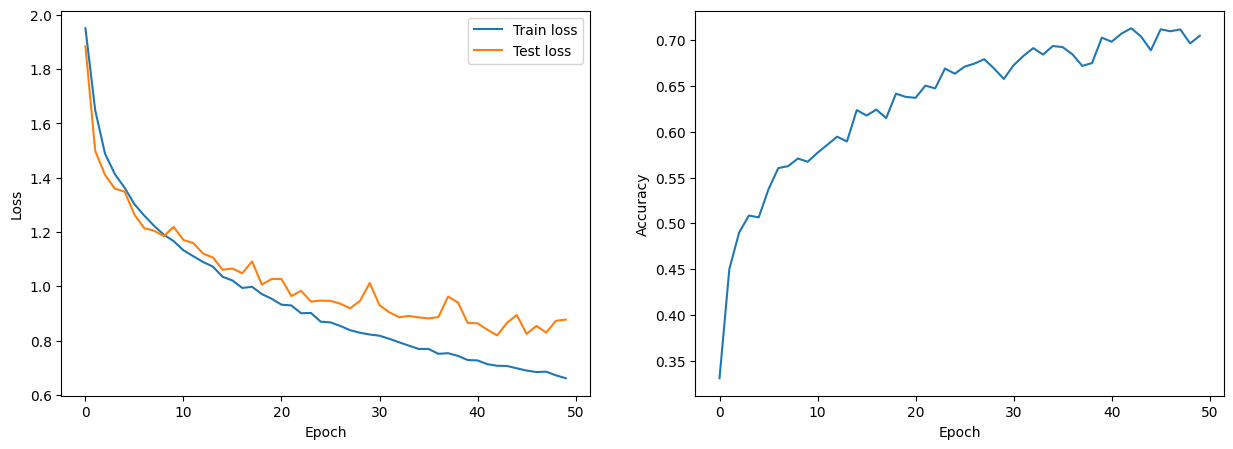

In [27]:
config, model, train_losses, test_losses, accuracies = load_experiment(exp_name)

import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(train_losses, label="Train loss")
ax1.plot(test_losses, label="Test loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax2.plot(accuracies)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
plt.savefig("metrics.png")
plt.show()

通过上图（训练 50 个 Epoch）可以发现，末期存在轻微过拟合。所以对于 CIFAR10 数据集，我们的 tiny ViT 模型大概适合 40 左右的总训练 epoch 数。

### 可视化注意力权重

我们在设计模型时保留了获取 attention probabilities 的接口。这里可以通过一次前向推理，获取模型对于不同图片中不同位置的注意力权重。通过插值和热图可以进行可视化。

`model(images, output_attentions=True)` 返回的 attention_maps 是一个列表，长度为 4，每个元素形状为：(batch_size, num_heads, sequence_length, sequence_length)

d:\ProgramData\Miniconda3\envs\d2l\lib\site-packages\torchvision\transforms\functional.py:154: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  img = torch.from_numpy(pic.transpose((2, 0, 1))).contiguous()


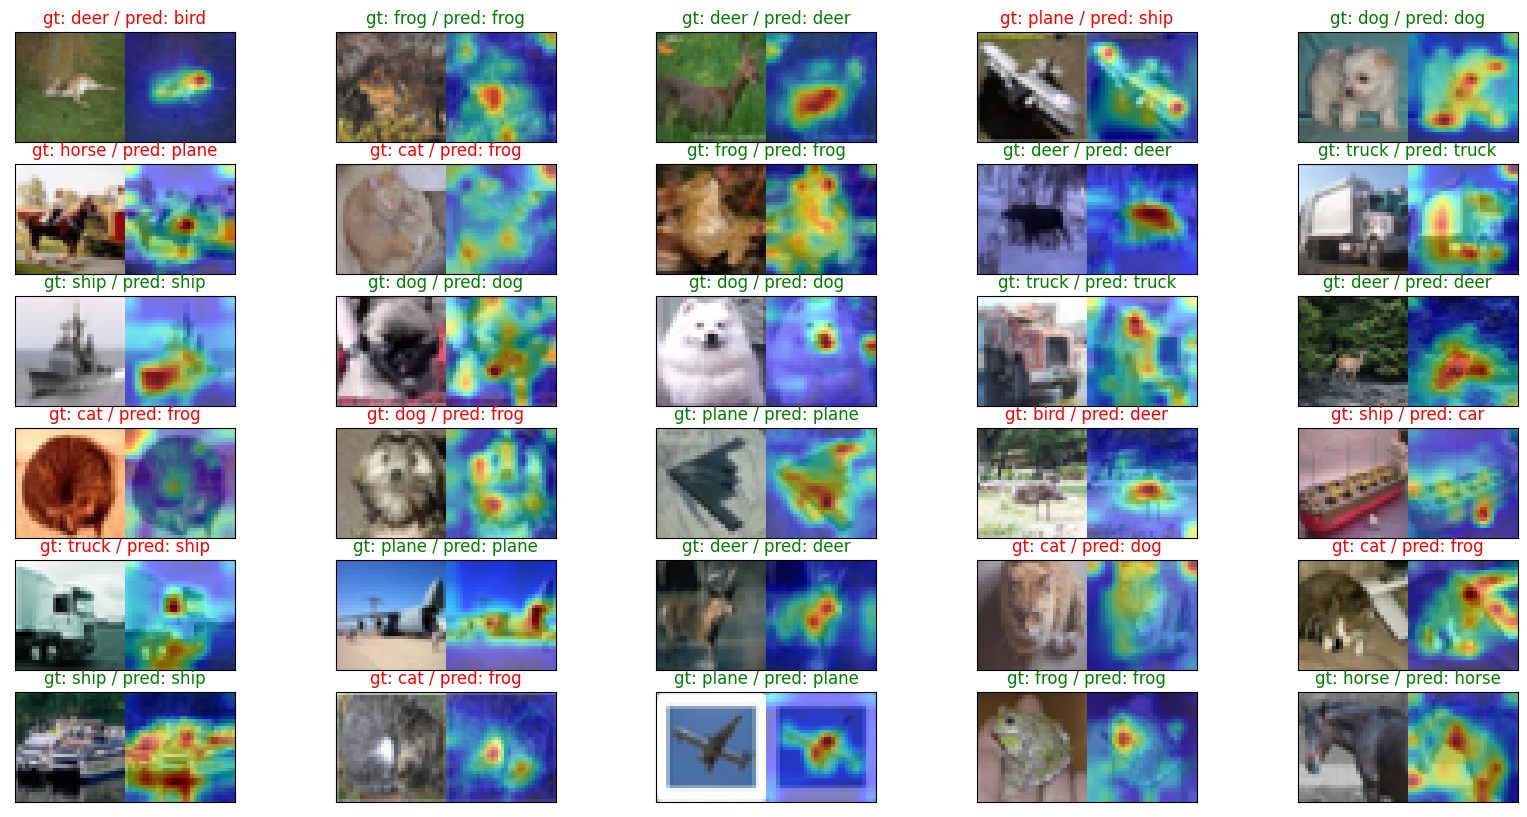

In [28]:
@torch.no_grad()
def visualize_attention(model, output=None, device="cuda"):
    model.eval()
    
    # 随机抽取 30 个测试集样本
    num_images = 30
    testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
    classes = ('plane', 'car', 'bird', 'cat',
            'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    indices = torch.randperm(len(testset))[:num_images]
    raw_images = [np.asarray(testset[i][0]) for i in indices]
    labels = [testset[i][1] for i in indices]
    # 做和训练时 测试集所做的相同的预处理
    test_transform = transforms.Compose(
        [transforms.ToTensor(),
        transforms.Resize((32, 32)),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
    images = torch.stack([test_transform(image) for image in raw_images])
    images = images.to(device)
    model = model.to(device)
    
    # 模型前向推理，取出注意力权重 ()
    logits, attention_maps = model(images, output_attentions=True)
    predictions = torch.argmax(logits, dim=1)
    # 拼接所有层的注意力，把列表变成一个张量
    attention_maps = torch.cat(attention_maps, dim=1)   # (batch_size, num_layers * num_heads, seq_len, seq_len)
    # 取出 cls token 的注意力，并去掉 cls token 对自己的注意力
    attention_maps = attention_maps[:, :, 0, 1:]    # (batch_size, num_layers * num_heads, num_patches)
    # 对所有层所有头取平均值
    attention_maps = attention_maps.mean(dim=1)     # (batch_size, num_patches)
    # 重排成 8 * 8 网络
    num_patches = attention_maps.size(-1)
    size = int(math.sqrt(num_patches))
    attention_maps = attention_maps.reshape(-1, size, size)
    # 双线性插值到原图大小 32×32
    # interpolate 只支持四维输入 (N, C, H, W)，所以需要添加通道维度
    attention_maps = attention_maps.unsqueeze(1)
    attention_maps = F.interpolate(attention_maps, size=(32, 32), mode='bilinear', align_corners=False)
    attention_maps = attention_maps.squeeze(1)
    
    # 绘制原图和 attention maps
    fig = plt.figure(figsize=(20, 10))
    # mask 用来屏蔽掉左半边的注意力热力图，只让热力图显示在右半边的图像上
    mask = np.concatenate([np.ones((32, 32)), np.zeros((32, 32))], axis=1)
    for i in range(num_images):
        # 添加子图，同时不打印刻度线
        ax = fig.add_subplot(6, 5, i+1, xticks=[], yticks=[])
        img = np.concatenate((raw_images[i], raw_images[i]), axis=1)
        ax.imshow(img)
        # 屏蔽掉左半边的注意力热力图
        extended_attention_map = np.concatenate((np.zeros((32, 32)), attention_maps[i].cpu()), axis=1)
        extended_attention_map = np.ma.masked_where(mask==1, extended_attention_map)
        # 在已经显示好的拼接原图上，再叠加一层注意力热力图
        ax.imshow(extended_attention_map, alpha=0.5, cmap='jet')
        # 添加标题，预测正确用绿色，预测错误用红色
        gt = classes[labels[i]]         # 真实类别名
        pred = classes[predictions[i]]  # 模型预测类别名
        ax.set_title(f"gt: {gt} / pred: {pred}", color=("green" if gt==pred else "red"))
    if output is not None:
        plt.savefig(output)
    plt.show()
    
visualize_attention(model)

## 改进方向

模型在测试集上的正确率达到约 70%，大概达到小型 CNN 的下限水准。
- 对于过拟合问题，我们的 config 中将两个 Dropout 概率都设置为 0，后续可以尝试**打开 Dropout**。
- **数据增强**上，还有很多适用于图片的方法，如亮度调整、偏色调整、图像混合等等，我们只用了最简单的水平翻转和裁切。CIFAR10 只有 50,000 个样本，训练数据通过数据增强，达到更大的等效样本量是很重要的。
- ViT 实际上在 Optimizer 上用了 **线性warmup + cosine decay** 的学习率调度算法，可以辅助优化器更好找到最优解。
- **模型还可以进一步加大**。目前使用 512 的 BatchSize 大概占用 4GB 显存。